# Flight Delay Prediction with Bio-Inspired Hyperparameter Optimization

**Presentation notebook — complete project overview**

This project predicts whether a flight to one of ten Balkan airports will arrive at least **15 minutes late**. It combines classical machine learning, leakage-safe air-transport network features, XGBoost, and nine hyperparameter optimization algorithms.

**Final result:** the optimized model detects **68.16%** of delayed flights and achieves **F1 = 0.4243** and **ROC-AUC = 0.7458** on the held-out 2023 test period.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve()
while not (ROOT / 'config' / 'default.yaml').exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError('Project root containing config/default.yaml was not found')
    ROOT = ROOT.parent

pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')

def load_json(relative_path):
    return json.loads((ROOT / relative_path).read_text(encoding='utf-8'))

print(f'Project root: {ROOT}')
print('This notebook reads saved results only; it does not train any model.')

Project root: C:\Users\Admin\Desktop\Bioloshki inspirirano presmetuvanje proekt
This notebook reads saved results only; it does not train any model.


## 1. Research question and workflow

**Research question:** Can recent delays across the European air-transport network improve the prediction of significant delays on flights to the Balkans?

The workflow was:

1. Audit and clean historical flight records.
2. Define significant delay as `delay_minutes >= 15`.
3. Split data chronologically into train, validation, and test periods.
4. Build Logistic Regression, Random Forest, and XGBoost baselines.
5. Add 144 leakage-safe network features from previous hours.
6. Optimize XGBoost with nine optimization algorithms under an equal budget.
7. Select the winner using validation F1 only.
8. Refit on train + validation and evaluate once on the held-out test period.

## 2. Dataset

The original data are NumPy files, one file per destination airport. Each raw row contains origin, destination, scheduled Unix timestamp, and delay in seconds. The source files were preserved unchanged; processing created a separate Parquet dataset.

In [2]:
audit = load_json('results/data_audit/summary.json')
airports = pd.read_csv(ROOT / 'results/data_audit/airport_summary.csv')
years = pd.read_csv(ROOT / 'results/data_audit/year_summary.csv')

overview = pd.DataFrame({
    'Item': [
        'Flight records', 'Balkan destinations', 'Unique origins', 'Unique routes',
        'First record (UTC)', 'Last record (UTC)', 'Delayed flights', 'Delayed share'
    ],
    'Value': [
        f"{audit['records']:,}", f"{audit['airports']}", f"{audit['origins']:,}",
        f"{audit['routes']:,}", audit['date_start_utc'][:10], audit['date_end_utc'][:10],
        f"{audit['delayed_records']:,}", f"{audit['delayed_percent']:.3f}%"
    ]
})
display(overview.style.hide(axis='index'))

display(Markdown('### Destination-level overview'))
display(airports[['destination', 'records', 'unique_origins', 'mean_delay_minutes',
                  'median_delay_minutes', 'delayed_percent']].sort_values('delayed_percent', ascending=False)
        .style.format({'records': '{:,.0f}', 'unique_origins': '{:,.0f}',
                       'mean_delay_minutes': '{:.2f}', 'median_delay_minutes': '{:.2f}',
                       'delayed_percent': '{:.2f}%'}).hide(axis='index'))

Item,Value
Flight records,"300,738"
Balkan destinations,10
Unique origins,790
Unique routes,"3,186"
First record (UTC),2015-03-01
Last record (UTC),2023-06-30
Delayed flights,"43,482"
Delayed share,14.458%


### Destination-level overview

destination,records,unique_origins,mean_delay_minutes,median_delay_minutes,delayed_percent
LQSA,"14,590",206,5.35,4.23,19.42%
BKPR,"21,144",212,4.63,3.42,17.69%
LDSP,"29,676",351,4.80,3.47,16.34%
LATI,"36,273",291,4.25,3.55,16.26%
LYTV,"13,840",292,3.64,2.15,15.69%
LWSK,"20,962",261,2.15,1.28,14.51%
LDDU,"22,518",338,3.36,2.25,14.07%
LDZA,"51,110",384,2.91,1.87,13.48%
LBSF,"67,914",499,0.62,-0.08,12.03%
LBBG,"22,711",352,0.16,-1.07,11.97%


## 3. Data preparation and quality checks

Processing standardized airport codes, converted timestamps to UTC datetimes, converted delay seconds to minutes, derived calendar features, created route identifiers, and created the binary target.

Positive delay values mean **late arrival**; negative values mean **early arrival**. A flight with `delay_minutes = 20` receives `is_delayed = 1`. A flight that is 10 minutes late receives `is_delayed = 0` because it does not cross the 15-minute threshold.

In [3]:
quality = pd.DataFrame({
    'Check': [
        'Missing core rows', 'Rows participating in duplicate pairs',
        'Repeated copies removed before modeling', 'Destination/file mismatches',
        'Extreme-delay rows flagged and retained'
    ],
    'Result': [
        audit['missing_core_rows'], audit['exact_duplicate_rows'], 6,
        audit['destination_mismatch_rows'], audit['extreme_delay_rows']
    ],
    'Decision': [
        'No removal needed', 'Six duplicate pairs were identified',
        'Keep the first copy only', 'No mismatch found',
        'Retained because they may represent real disruptions'
    ]
})
display(quality.style.hide(axis='index'))

Check,Result,Decision
Missing core rows,0,No removal needed
Rows participating in duplicate pairs,12,Six duplicate pairs were identified
Repeated copies removed before modeling,6,Keep the first copy only
Destination/file mismatches,0,No mismatch found
Extreme-delay rows flagged and retained,12,Retained because they may represent real disruptions


## 4. Exploratory data analysis

The delay distribution is concentrated near zero and has a long right tail. Delay rates differ across destinations. The record count drops sharply in 2020, consistent with the COVID-19 disruption; 2015 starts in March and 2023 contains only January–June.

### Delay distribution

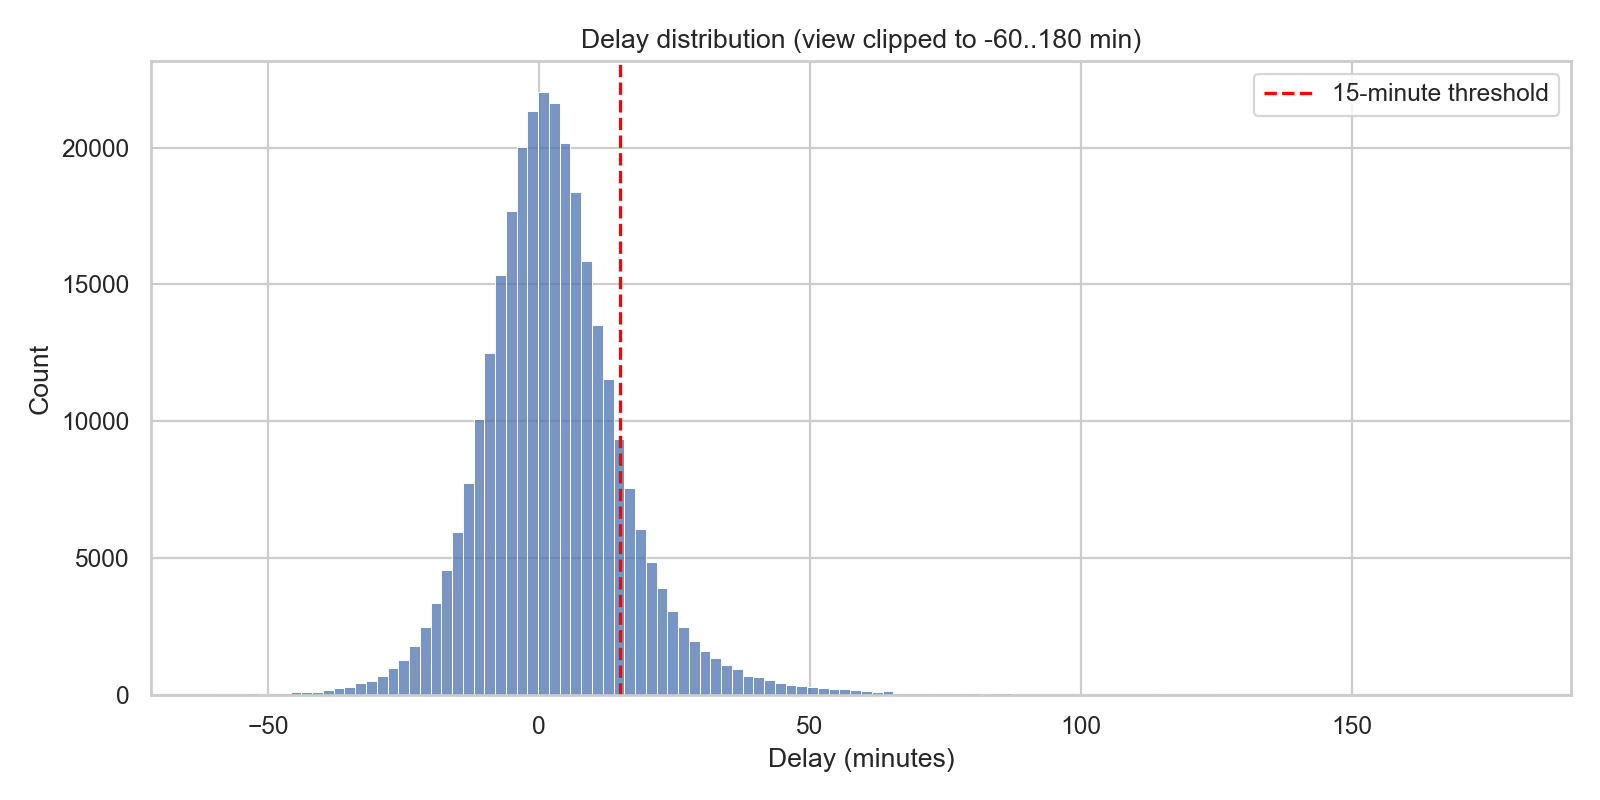

### Flights delayed at least 15 minutes by destination

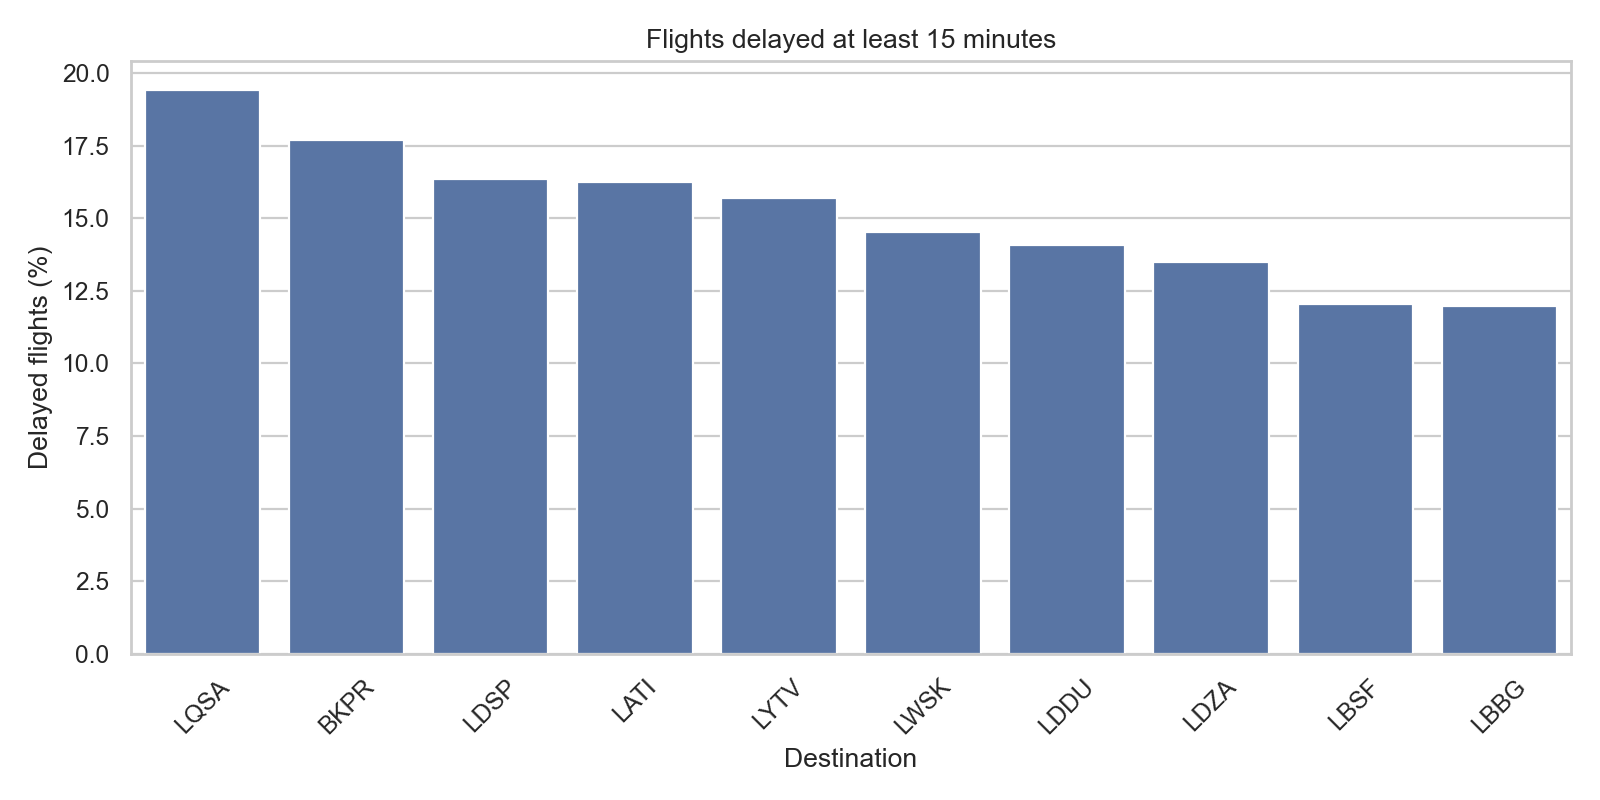

### Available records by year

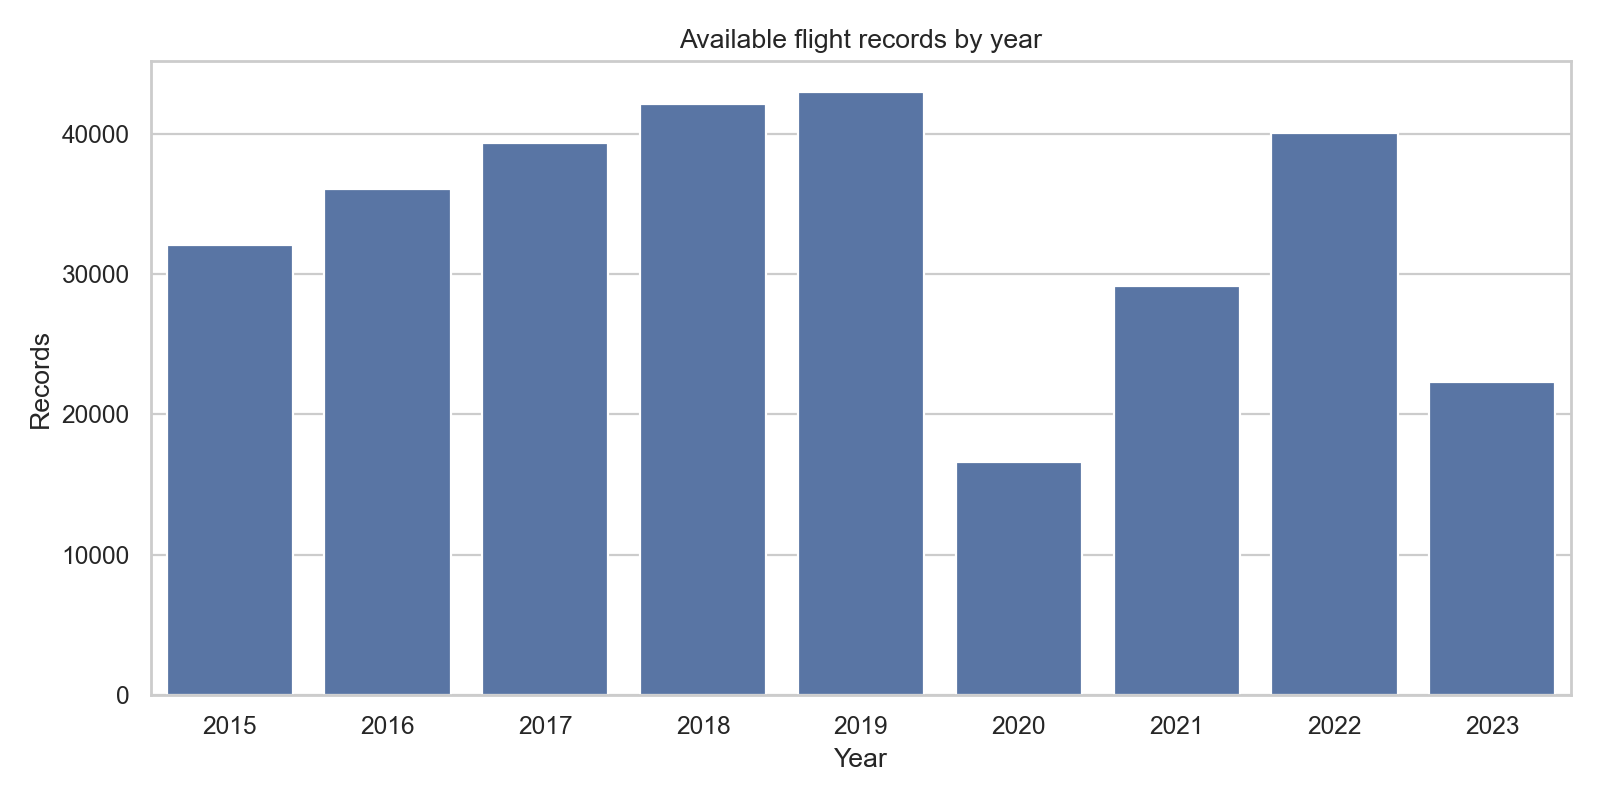

### Exact yearly record counts and delay rates

year,records,delayed_percent
2015,"32,092",13.181%
2016,"36,055",12.803%
2017,"39,323",13.682%
2018,"42,114",17.189%
2019,"43,020",16.116%
2020,"16,570",5.432%
2021,"29,151",9.125%
2022,"40,074",19.062%
2023,"22,339",17.391%


In [4]:
for title, filename in [
    ('Delay distribution', 'delay_distribution.png'),
    ('Flights delayed at least 15 minutes by destination', 'delayed_rate_by_airport.png'),
    ('Available records by year', 'records_by_year.png'),
]:
    display(Markdown(f'### {title}'))
    display(Image(filename=str(ROOT / 'results/data_audit' / filename)))

display(Markdown('### Exact yearly record counts and delay rates'))
display(years.style.format({'records': '{:,.0f}', 'delayed_percent': '{:.3f}%'}).hide(axis='index'))

## 5. Leakage-safe temporal split

A random split would mix past and future flights. Instead, the model learns from the past and is evaluated on later periods. The test period is never available to hyperparameter optimizers.

In [5]:
split_table = pd.DataFrame({
    'Split': ['Train', 'Validation', 'Test'],
    'Period': ['2015–2021', '2022', 'January–June 2023'],
    'Records': [238_320, 40_073, 22_339],
    'Delayed records': [31_957, 7_639, 3_885],
    'Purpose': ['Fit model parameters', 'Select features and hyperparameters', 'One-time final evaluation']
})
split_table['Delayed share'] = 100 * split_table['Delayed records'] / split_table['Records']
display(split_table.style.format({'Records': '{:,.0f}', 'Delayed records': '{:,.0f}',
                                  'Delayed share': '{:.2f}%'}).hide(axis='index'))

Split,Period,Records,Delayed records,Purpose,Delayed share
Train,2015–2021,"238,320","31,957",Fit model parameters,13.41%
Validation,2022,"40,073","7,639",Select features and hyperparameters,19.06%
Test,January–June 2023,"22,339","3,885",One-time final evaluation,17.39%


## 6. Features

### Basic flight features

- Origin, destination, and route
- Destination-local year, month, weekday, and hour
- Weekend indicator and season

Categorical values are converted with one-hot encoding. `delay_minutes` is **not** an input feature because using it would reveal the target.

### Network features

For 10 European and 10 Balkan airports, the model receives delay and activity information from 1, 2, and 3 hours before the flight. Regional aggregates include mean and maximum delay, active-airport count, delayed-airport count, and rolling 3-hour and 6-hour summaries.

This creates **144 network features**. A flight in hour `t` only uses information from completed hours before `t`; current and future information is excluded. `active = 0` with `delay = null` means that the airport had no activity, not zero delay.

## 7. Baseline models

Logistic Regression was the first true ML baseline. Because delayed flights are the minority class, a class-balanced version was also tested. Random Forest and a fixed-parameter XGBoost were then evaluated under the same temporal split and feature set.

Model,precision,recall,f1,roc_auc,accuracy
Logistic Regression,0.7606,0.0368,0.0702,0.7057,0.8305
Balanced Logistic Regression,0.3101,0.5452,0.3954,0.7036,0.7100
Random Forest,0.3926,0.2046,0.2690,0.6875,0.8066
Base XGBoost,0.3742,0.2185,0.2759,0.6996,0.8005


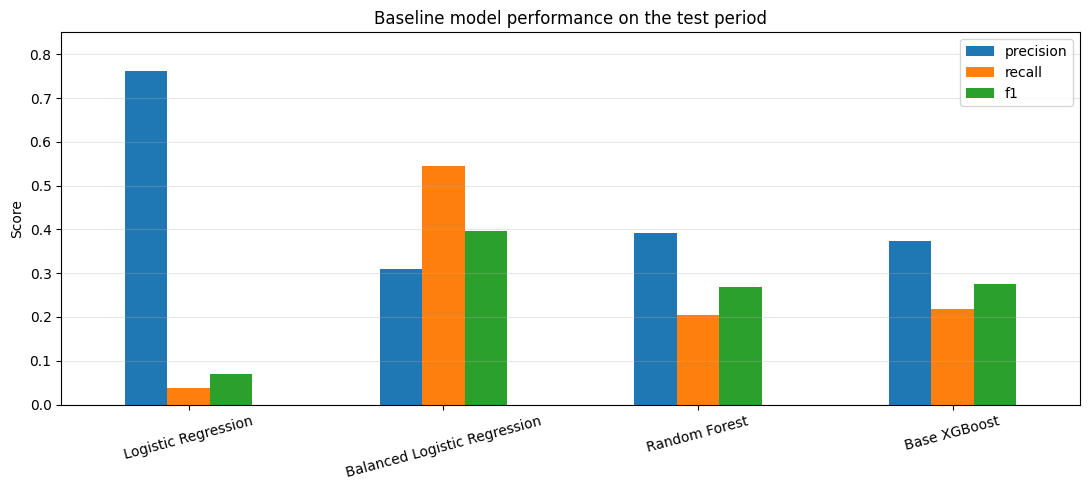

In [6]:
model_results = pd.read_csv(ROOT / 'results/model_comparison/comparison.csv')
test_models = model_results.query("split == 'test'").copy()
labels = {
    'logistic_standard': 'Logistic Regression',
    'logistic_balanced': 'Balanced Logistic Regression',
    'random_forest': 'Random Forest',
    'xgboost': 'Base XGBoost',
}
test_models['Model'] = test_models['model'].map(labels)
columns = ['Model', 'precision', 'recall', 'f1', 'roc_auc', 'accuracy']
display(test_models[columns].style.format({column: '{:.4f}' for column in columns[1:]}).hide(axis='index'))

plot_data = test_models.set_index('Model')[['precision', 'recall', 'f1']]
ax = plot_data.plot(kind='bar', figsize=(11, 5), rot=15)
ax.set(title='Baseline model performance on the test period', ylabel='Score', xlabel='')
ax.set_ylim(0, 0.85)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation:** Standard Logistic Regression has high accuracy and precision but detects only 3.68% of delayed flights. Balancing increases recall to 54.52% and F1 to 0.3954. The initial tree models do not yet outperform the balanced logistic baseline. XGBoost is retained because it can model nonlinear interactions and is well suited to the continuous network features and hyperparameter optimization stage.

## 8. Do network features help?

To isolate the effect of network context, the same fixed XGBoost configuration was evaluated with and without the 144 new features.

Model,precision,recall,f1,roc_auc,accuracy
Base XGBoost,0.3742,0.2185,0.2759,0.6996,0.8005
XGBoost + network features,0.2715,0.7326,0.3962,0.7214,0.6116


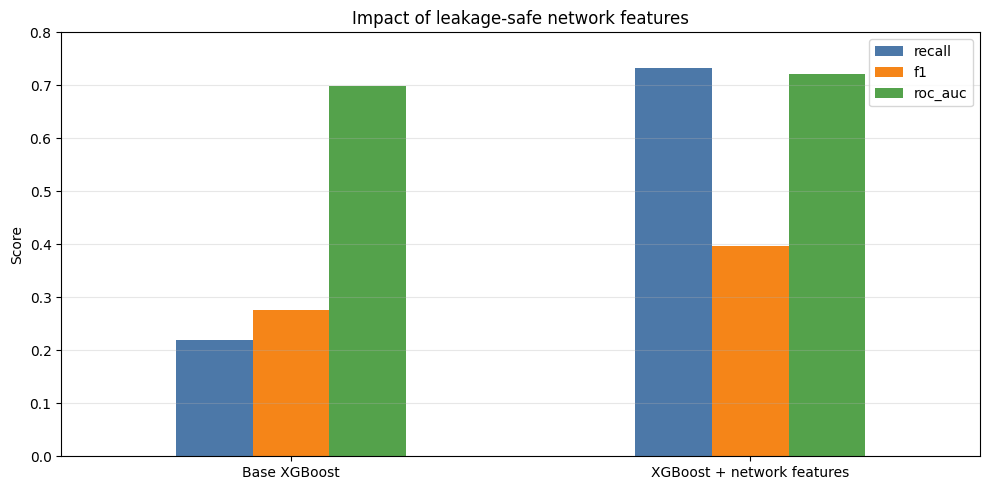

Delayed flights detected by base XGBoost: 849 / 3,885
Delayed flights detected with network features: 2,846 / 3,885


In [7]:
network_results = pd.read_csv(ROOT / 'results/network_xgboost/comparison.csv')
network_test = network_results.query("split == 'test'").copy()
network_test['Model'] = network_test['model'].map({
    'xgboost_base': 'Base XGBoost',
    'xgboost_network': 'XGBoost + network features'
})
columns = ['Model', 'precision', 'recall', 'f1', 'roc_auc', 'accuracy']
display(network_test[columns].style.format({column: '{:.4f}' for column in columns[1:]}).hide(axis='index'))

ax = network_test.set_index('Model')[['recall', 'f1', 'roc_auc']].plot(
    kind='bar', figsize=(10, 5), rot=0, color=['#4C78A8', '#F58518', '#54A24B'])
ax.set(title='Impact of leakage-safe network features', ylabel='Score', xlabel='')
ax.set_ylim(0, 0.8)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print('Delayed flights detected by base XGBoost: 849 / 3,885')
print('Delayed flights detected with network features: 2,846 / 3,885')

## 9. Hyperparameter optimization

The objective is to **maximize validation F1 at classification threshold 0.5**. Every optimizer receives the same data, search space, fixed XGBoost settings, and budget of 32 objective calls.

| Hyperparameter | Range | Meaning |
|---|---:|---|
| `max_depth` | 3–10 | Tree complexity |
| `learning_rate` | 0.02–0.30 (log scale) | Contribution of each tree |
| `min_child_weight` | 1–10 | Minimum evidence required for a split |
| `subsample` | 0.60–1.00 | Fraction of training rows per tree |
| `scale_pos_weight` | 1.0–6.5 | Weight assigned to delayed flights |

Fixed settings: 300 trees, `colsample_bytree=0.8`, and histogram tree construction. Test data are not loaded by the optimization objective.

### Nine optimization algorithms

1. **Grid Search (GS):** systematic coarse grid.
2. **Random Search (RS):** random configurations.
3. **Hill Climbing (HC):** accepts local improvements.
4. **Tabu Search (TS):** local search with short-term memory.
5. **Genetic Algorithm (GA):** population, selection, crossover, and mutation.
6. **Particle Swarm Optimization (PSO):** particles follow personal and global best positions.
7. **SciPy/Nelder–Mead (SOpt):** moves a simplex using reflection, expansion, and contraction.
8. **Simulated Annealing (SA):** can temporarily accept worse solutions to escape local optima.
9. **Bayesian/TPE:** uses previous evaluations to propose promising configurations.

GA and PSO are biologically inspired; SA is physically inspired; the remaining methods provide classical and probabilistic comparison baselines.

Rank,Algorithm,best_validation_f1,model_fits,cache_hits,Time (min)
1,Bayesian/TPE,0.433229,32,0,9.19
2,Simulated Annealing,0.431350,32,0,8.56
3,Genetic Algorithm,0.430916,32,0,10.29
4,Tabu Search,0.429512,25,7,6.90
5,Hill Climbing,0.428913,25,7,11.98
6,Particle Swarm,0.427076,30,2,14.52
7,Random Search,0.425455,32,0,18.74
8,Grid Search,0.423994,32,0,20.03
9,SciPy/Nelder–Mead,0.420976,32,0,9.32


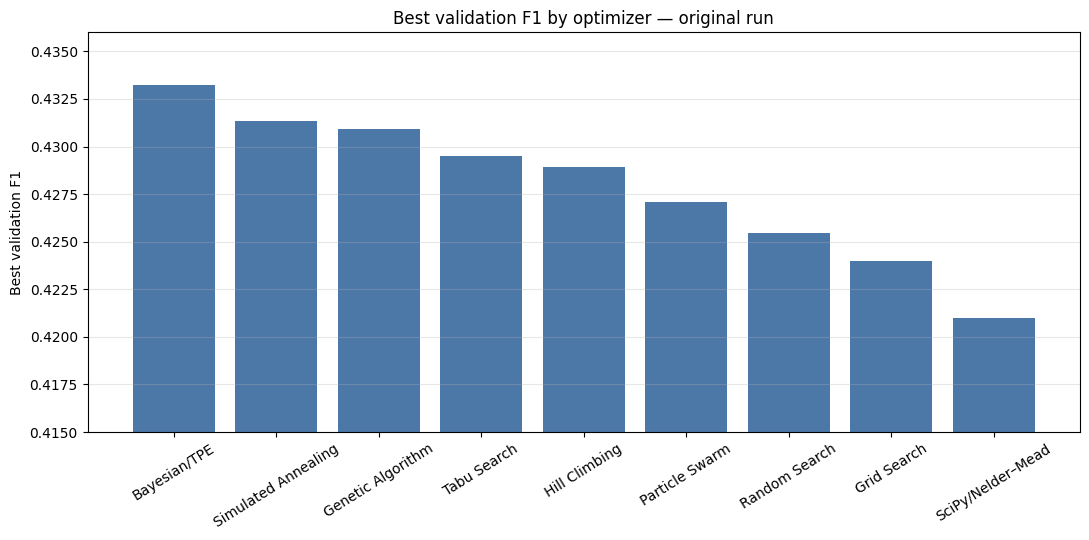

In [8]:
optimization = pd.read_csv(ROOT / 'results/optimization_full/comparison.csv')
algorithm_labels = {
    'bayesian_tpe': 'Bayesian/TPE',
    'simulated_annealing': 'Simulated Annealing',
    'genetic_algorithm': 'Genetic Algorithm',
    'tabu_search': 'Tabu Search',
    'hill_climbing': 'Hill Climbing',
    'particle_swarm': 'Particle Swarm',
    'random_search': 'Random Search',
    'grid_search': 'Grid Search',
    'scipy_nelder_mead': 'SciPy/Nelder–Mead',
}
optimization['Algorithm'] = optimization['algorithm'].map(algorithm_labels)
optimization['Time (min)'] = optimization['seconds'] / 60
optimization.insert(0, 'Rank', range(1, len(optimization) + 1))
display(optimization[['Rank', 'Algorithm', 'best_validation_f1', 'model_fits', 'cache_hits', 'Time (min)']]
        .style.format({'best_validation_f1': '{:.6f}', 'Time (min)': '{:.2f}'}).hide(axis='index'))

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.bar(optimization['Algorithm'], optimization['best_validation_f1'], color='#4C78A8')
ax.set(title='Best validation F1 by optimizer — original run', ylabel='Best validation F1', xlabel='')
ax.set_ylim(0.415, 0.436)
ax.tick_params(axis='x', rotation=32)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Convergence over the 32 objective calls

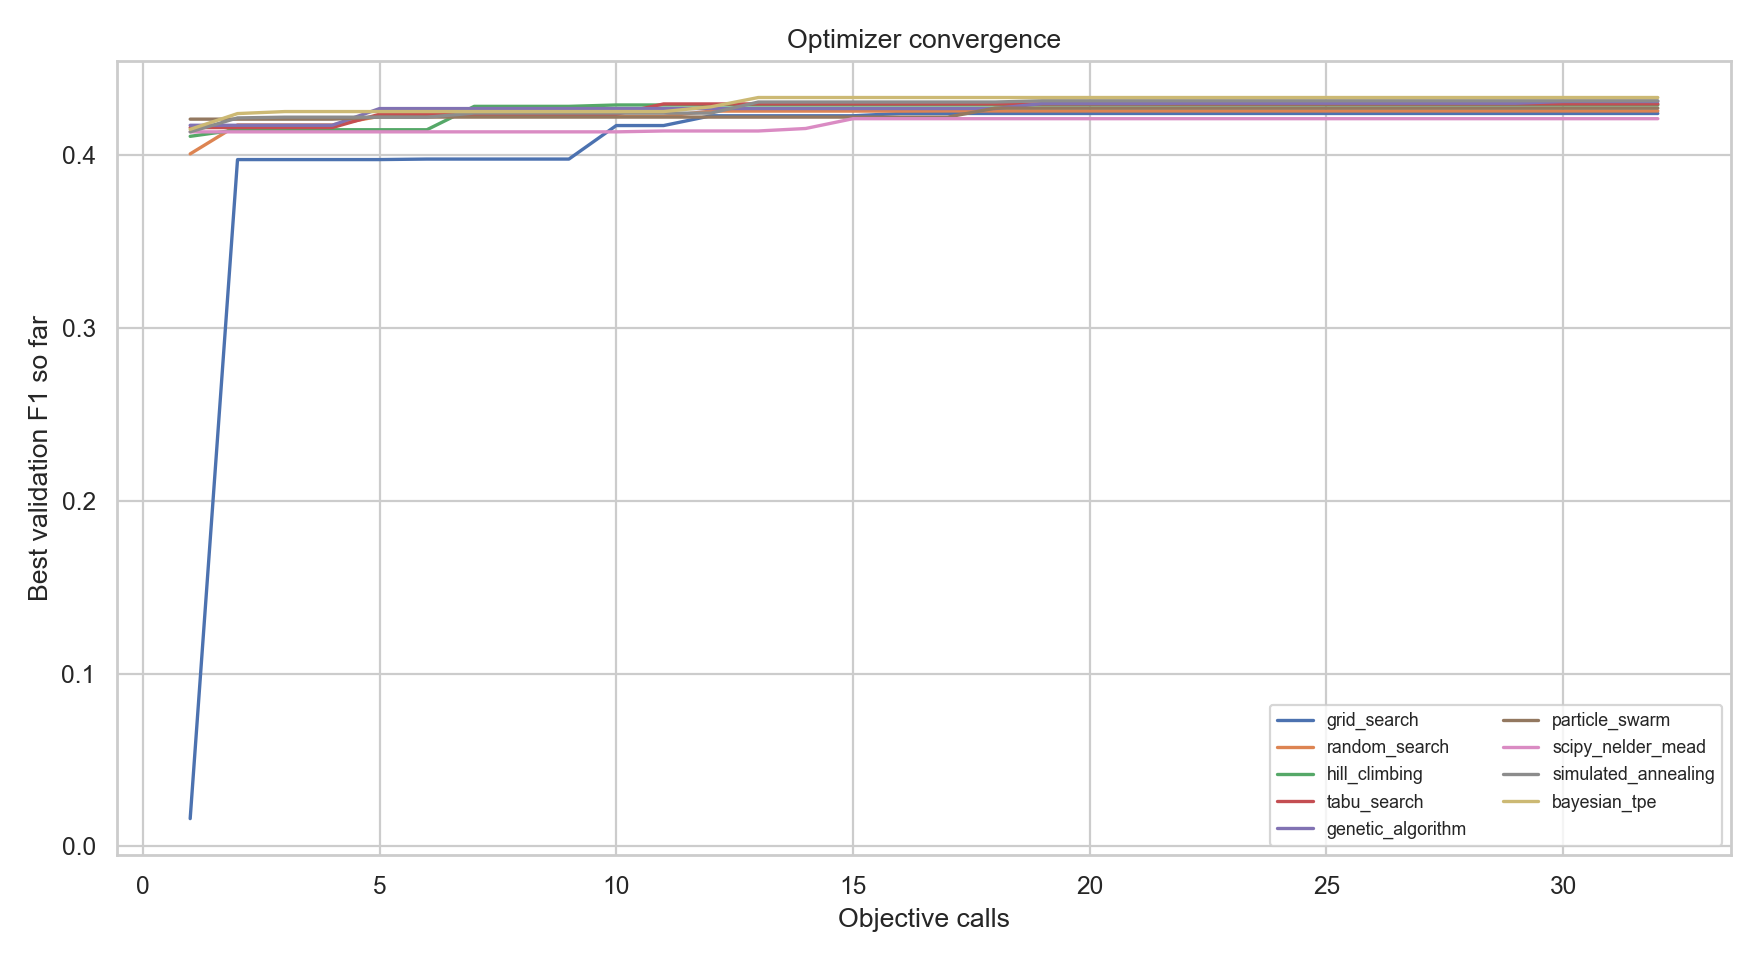

A rising line means that an optimizer found a better validation F1; a flat section means no improvement.


In [9]:
display(Markdown('### Convergence over the 32 objective calls'))
display(Image(filename=str(ROOT / 'results/optimization_full/convergence.png')))
print('A rising line means that an optimizer found a better validation F1; a flat section means no improvement.')

## 10. Seed stability analysis

Randomized optimizers can produce different results from different initial conditions. Seeds 100 and 101 were therefore executed separately for all nine algorithms, again with 32 validation evaluations each.

The table with `runs = 3` combines the original run, seed 100, and seed 101. The original experiment used algorithm-specific seeds 42–49, while the two additional experiments use shared seeds 100 and 101. Three runs provide a more useful stability estimate, although the sample is still too small for strong statistical significance claims.

### Seed 100 results

Rank,Algorithm,best_validation_f1,Time (min)
1,Genetic Algorithm,0.432057,6.52
2,Bayesian/TPE,0.431889,7.16
3,Hill Climbing,0.431463,6.36
4,Tabu Search,0.430445,6.94
5,Simulated Annealing,0.429810,6.23
6,Random Search,0.427944,9.22
7,Particle Swarm,0.424970,10.93
8,Grid Search,0.422497,9.74
9,SciPy/Nelder–Mead,0.419702,8.16


### Seed 101 results

Rank,Algorithm,best_validation_f1,Time (min)
1,Tabu Search,0.429367,6.83
2,Hill Climbing,0.427622,5.40
3,Particle Swarm,0.426498,10.50
4,Bayesian/TPE,0.424652,8.66
5,Simulated Annealing,0.424472,6.71
6,Grid Search,0.424447,9.56
7,Genetic Algorithm,0.423896,7.96
8,Random Search,0.422947,9.34
9,SciPy/Nelder–Mead,0.421830,8.10


### Mean ± standard deviation across three completed runs

Rank,Algorithm,runs,f1_mean,f1_std,f1_best,f1_worst
1,Bayesian/TPE,3,0.429923,0.004614,0.433229,0.424652
2,Tabu Search,3,0.429775,0.000585,0.430445,0.429367
3,Hill Climbing,3,0.429332,0.001955,0.431463,0.427622
4,Genetic Algorithm,3,0.428956,0.004420,0.432057,0.423896
5,Simulated Annealing,3,0.428544,0.003609,0.431350,0.424472
6,Particle Swarm,3,0.426181,0.001088,0.427076,0.424970
7,Random Search,3,0.425449,0.002499,0.427944,0.422947
8,Grid Search,3,0.423646,0.001020,0.424447,0.422497
9,SciPy/Nelder–Mead,3,0.420836,0.001071,0.421830,0.419702


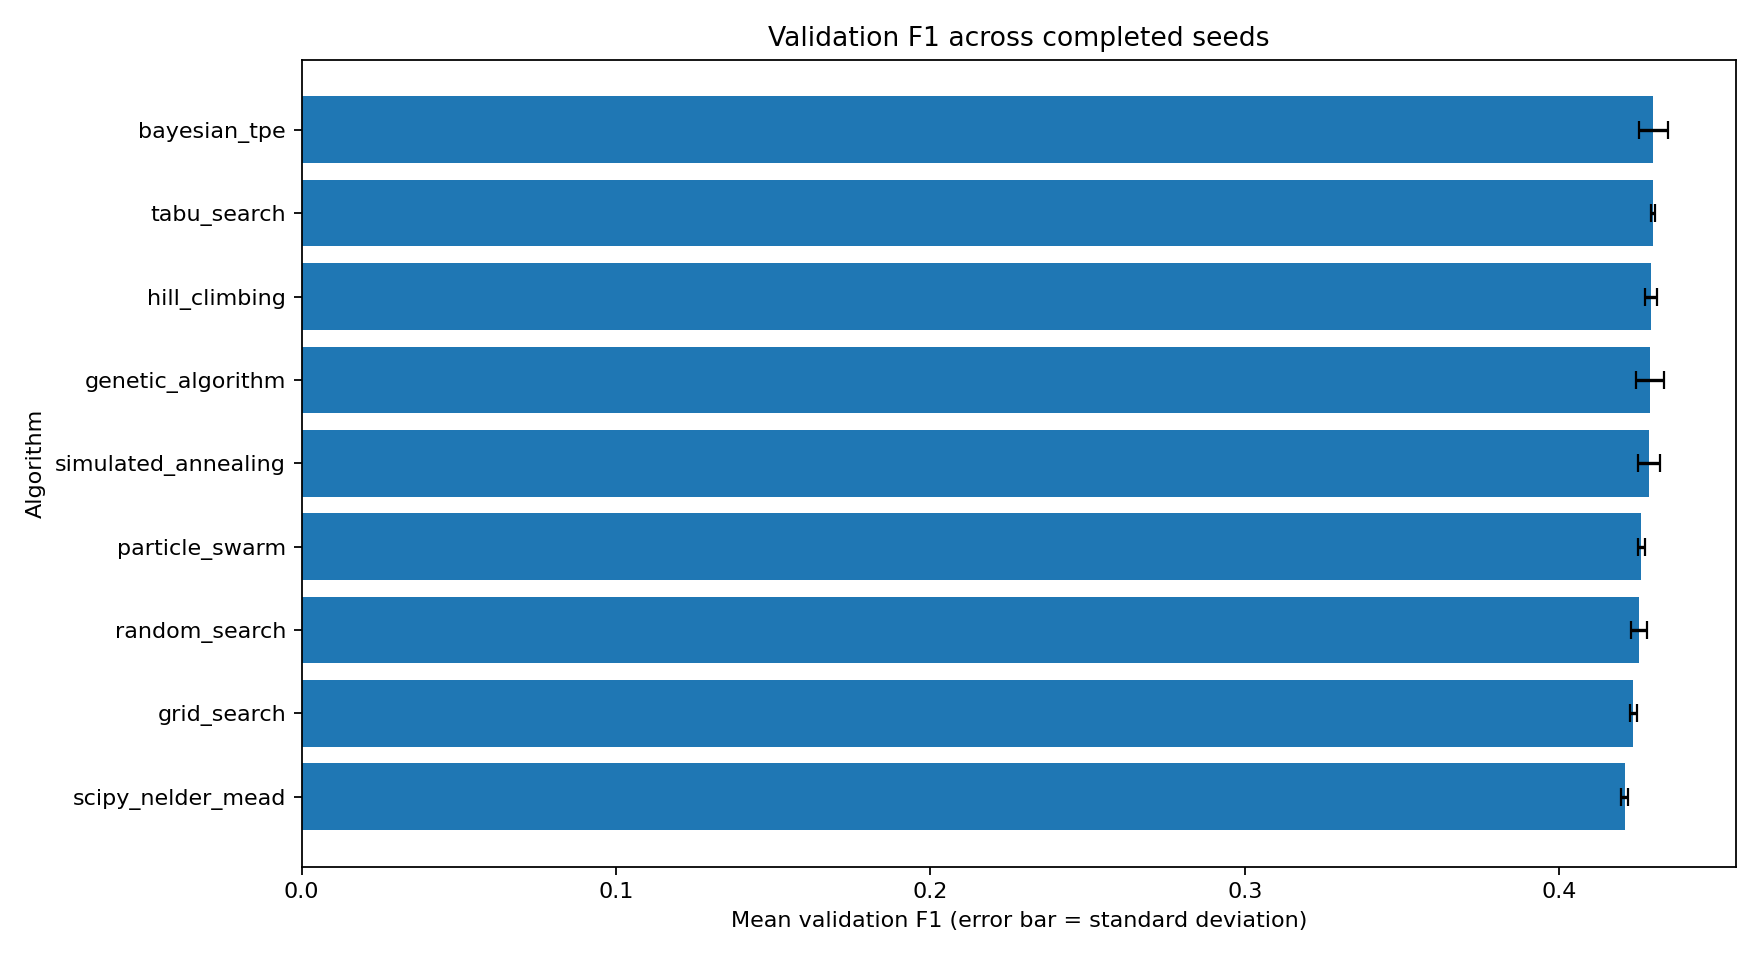

In [10]:
runs = pd.read_csv(ROOT / 'results/optimization_multiseed/runs.csv')
seed_100 = runs.query("seed == 100").sort_values('best_validation_f1', ascending=False).copy()
seed_100['Algorithm'] = seed_100['algorithm'].map(algorithm_labels)
seed_100.insert(0, 'Rank', range(1, len(seed_100) + 1))
seed_100['Time (min)'] = seed_100['seconds'] / 60

display(Markdown('### Seed 100 results'))
display(seed_100[['Rank', 'Algorithm', 'best_validation_f1', 'Time (min)']]
        .style.format({'best_validation_f1': '{:.6f}', 'Time (min)': '{:.2f}'}).hide(axis='index'))

seed_101 = runs.query("seed == 101").sort_values('best_validation_f1', ascending=False).copy()
seed_101['Algorithm'] = seed_101['algorithm'].map(algorithm_labels)
seed_101.insert(0, 'Rank', range(1, len(seed_101) + 1))
seed_101['Time (min)'] = seed_101['seconds'] / 60
display(Markdown('### Seed 101 results'))
display(seed_101[['Rank', 'Algorithm', 'best_validation_f1', 'Time (min)']]
        .style.format({'best_validation_f1': '{:.6f}', 'Time (min)': '{:.2f}'}).hide(axis='index'))

seed_summary = pd.read_csv(ROOT / 'results/optimization_multiseed/summary.csv')
seed_summary['Algorithm'] = seed_summary['algorithm'].map(algorithm_labels)
seed_summary.insert(0, 'Rank', range(1, len(seed_summary) + 1))
display(Markdown('### Mean ± standard deviation across three completed runs'))
display(seed_summary[['Rank', 'Algorithm', 'runs', 'f1_mean', 'f1_std', 'f1_best', 'f1_worst']]
        .style.format({'f1_mean': '{:.6f}', 'f1_std': '{:.6f}',
                       'f1_best': '{:.6f}', 'f1_worst': '{:.6f}'}).hide(axis='index'))

display(Image(filename=str(ROOT / 'results/optimization_multiseed/mean_f1_with_std.png')))

**Seed interpretation:** Genetic Algorithm is best on seed 100 with F1 = 0.432057, while Tabu Search is best on seed 101 with F1 = 0.429367. Across all three completed runs, Bayesian/TPE has the highest mean F1 (0.429923), but Tabu Search is almost tied (0.429775) and has the smallest standard deviation among the leading methods (0.000585). Therefore, Bayesian/TPE has the best observed mean, while Tabu Search is the most stable leading optimizer; the difference is too small to claim a statistically decisive winner.

## 11. Validation-selected winner and final evaluation

The original winner was selected strictly by validation F1. Bayesian/TPE selected a moderate tree depth, relatively high learning rate, near-full row subsampling, and a positive-class weight of approximately 4.4. The test period was still sealed at this point.

In [11]:
final_result = load_json('results/optimization_full/final_test_metrics.json')
winner_params = pd.DataFrame({
    'Hyperparameter': list(final_result['selected_params']),
    'Selected value': list(final_result['selected_params'].values())
})
display(Markdown(f"**Selected optimizer:** `{final_result['selected_optimizer']}`  \n**Validation F1:** `{final_result['selected_validation_f1']:.6f}`"))
display(winner_params.style.format({'Selected value': '{:.6f}'}).hide(axis='index'))
print(f"Final refit records: {final_result['refit_records']:,} (train + validation, 2015–2022)")

**Selected optimizer:** `bayesian_tpe`  
**Validation F1:** `0.433229`

Hyperparameter,Selected value
max_depth,5.000000
learning_rate,0.178016
min_child_weight,5.604839
subsample,0.943858
scale_pos_weight,4.396585


Final refit records: 278,393 (train + validation, 2015–2022)


Metric,Score
Accuracy,0.678320
Precision,0.308014
Recall,0.681596
F1,0.424291
ROC-AUC,0.745772


Test records: 22,339
Actually delayed: 3,885 (17.39%)
Predicted delayed: 38.48%
Correctly detected delayed flights: 2,648 / 3,885


### Final test confusion matrix

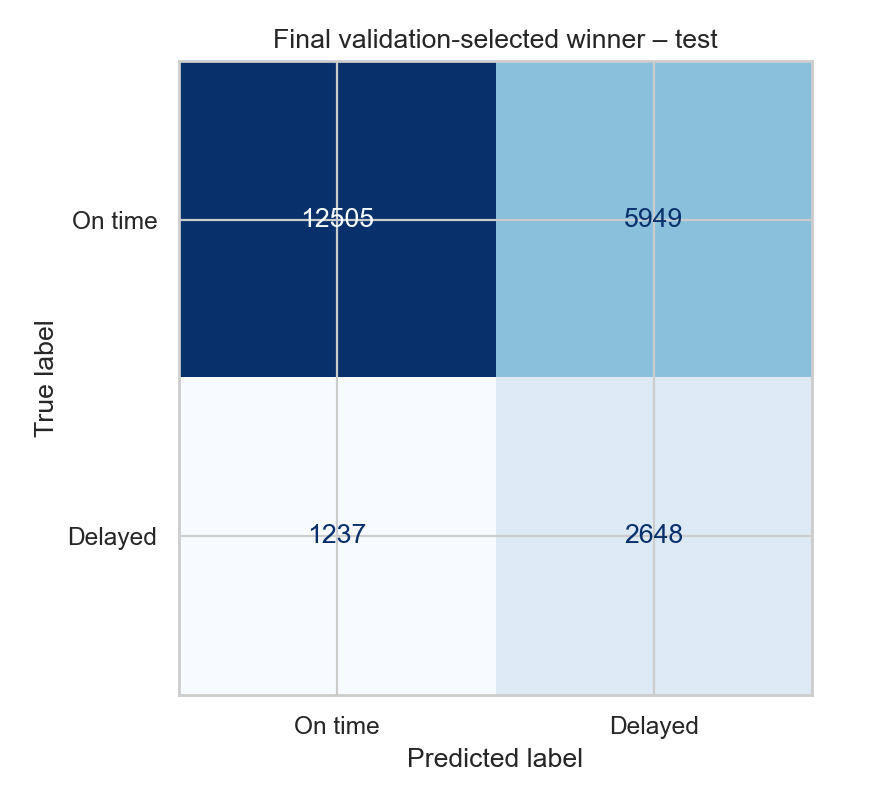

### Final test ROC curve

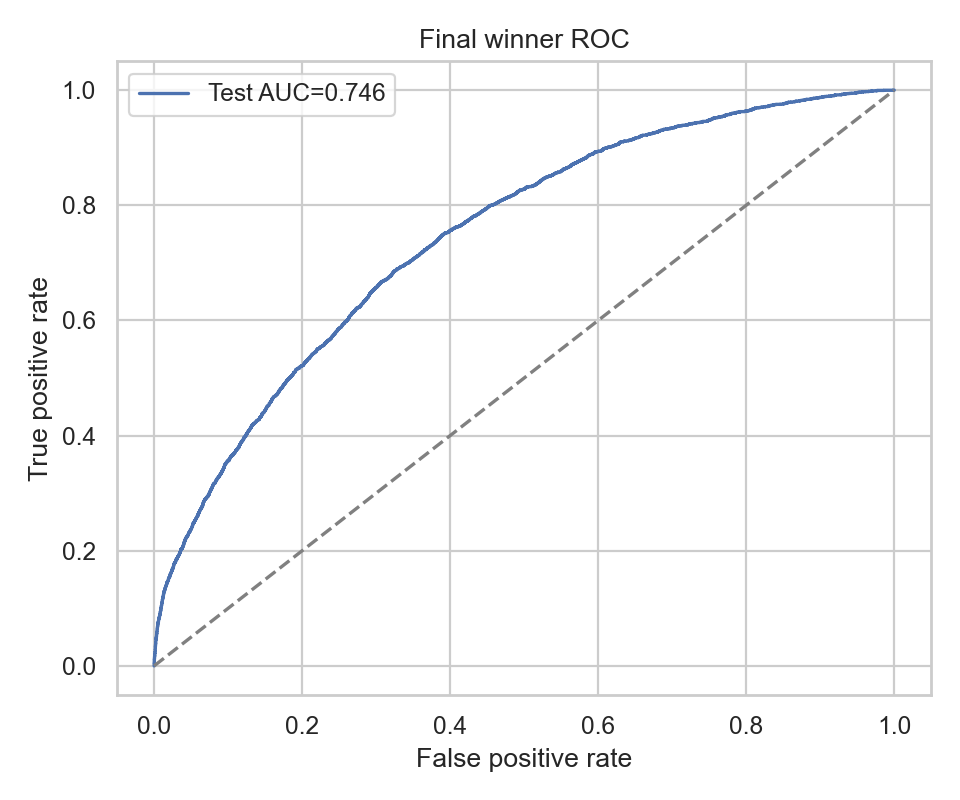

In [12]:
test = final_result['test']
final_metrics = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC'],
    'Score': [test['accuracy'], test['precision'], test['recall'], test['f1'], test['roc_auc']]
})
display(final_metrics.style.format({'Score': '{:.6f}'}).hide(axis='index'))

print(f"Test records: {test['records']:,}")
print(f"Actually delayed: {test['positive_records']:,} ({test['positive_percent']:.2f}%)")
print(f"Predicted delayed: {test['predicted_positive_percent']:.2f}%")
print(f"Correctly detected delayed flights: {test['confusion_matrix'][1][1]:,} / {test['positive_records']:,}")

display(Markdown('### Final test confusion matrix'))
display(Image(filename=str(ROOT / 'results/optimization_full/final_winner/confusion_matrix_test.png')))
display(Markdown('### Final test ROC curve'))
display(Image(filename=str(ROOT / 'results/optimization_full/final_winner/roc_test.png')))

Stage,F1,Recall,ROC-AUC
Base XGBoost,0.2759,0.2185,0.6996
XGBoost + network features,0.3962,0.7326,0.7214
Optimized final XGBoost,0.4243,0.6816,0.7458


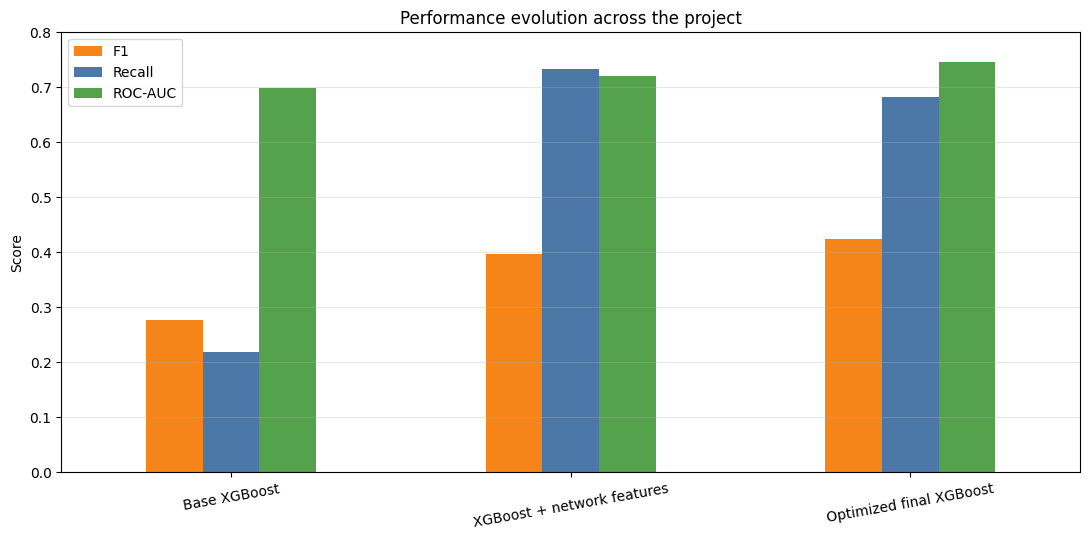

In [13]:
evolution = pd.DataFrame({
    'Stage': ['Base XGBoost', 'XGBoost + network features', 'Optimized final XGBoost'],
    'F1': [0.275918, 0.396158, test['f1']],
    'Recall': [0.218533, 0.732561, test['recall']],
    'ROC-AUC': [0.699605, 0.721433, test['roc_auc']]
})
display(evolution.style.format({column: '{:.4f}' for column in ['F1', 'Recall', 'ROC-AUC']}).hide(axis='index'))

ax = evolution.set_index('Stage')[['F1', 'Recall', 'ROC-AUC']].plot(
    kind='bar', figsize=(11, 5.5), rot=10, color=['#F58518', '#4C78A8', '#54A24B'])
ax.set(title='Performance evolution across the project', ylabel='Score', xlabel='')
ax.set_ylim(0, 0.8)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 12. Main conclusions

1. Calendar and route information provide useful but limited predictive signal.
2. Leakage-safe network features substantially improve delayed-flight detection: recall rises from 21.85% to 73.26% for the fixed XGBoost experiment.
3. Hyperparameter optimization further improves the final balance of precision and recall.
4. Bayesian/TPE wins the original run, Genetic Algorithm wins seed 100, and Tabu Search wins seed 101. Bayesian/TPE has the highest three-run mean, while Tabu Search is the most stable leading method.
5. The final model detects 68.16% of delayed flights, with F1 = 0.4243 and ROC-AUC = 0.7458.

### Limitations

- Weather, airline, aircraft type, and operational cause data are unavailable.
- Precision remains modest because the model produces many false positives.
- The classification threshold is fixed at 0.5.
- Multi-seed statistics contain three runs, which is useful for stability analysis but still limited for formal significance testing.
- Results apply to this dataset, airport set, and historical period.

### Short presentation summary

> We used 300,738 historical flights to ten Balkan airports and defined significant delay as at least 15 minutes. After chronological splitting, we compared classical ML baselines, then enriched XGBoost with 144 features describing delay activity across twenty airports in previous hours. The network features strongly improved delayed-flight detection. Nine optimization algorithms searched the same five-dimensional XGBoost hyperparameter space under an equal budget of 32 evaluations. Across three runs, Bayesian/TPE achieved the highest mean validation F1, while Tabu Search was almost tied and more stable. The final validation-selected model was refitted on 2015–2022 and evaluated once on 2023, achieving F1 0.4243, ROC-AUC 0.7458, and recall 68.16%.